# NB03 — Mini U-Net con conexiones skip (Modelo A1)

**MIA-07 · Examen Final · Proyecto Crack-Seg · Etapa 3 (Integrante 3)**

Este notebook construye, entrena y valida la **Mini U-Net (A1)**, que se compara con el
**Encoder-Decoder sin skip (A0)** entregado en la Etapa 2 (`NB02_EncoderDecoder_v2.ipynb`).

**Única diferencia arquitectónica con A0:** las conexiones skip (concatenación de las
características del Encoder en el Decoder). Todo lo demás se mantiene igual:

| Elemento | A0 (NB02) | A1 (este notebook) |
|---|---|---|
| Dataset | Crack-Seg completo v1: 3717 TRAIN / 199 VAL | **igual** |
| Resolución / batch | 416 × 416 / 4 | **igual** |
| Canales base / niveles | 16–32–64 / 2 reducciones | **igual** |
| Upsampling | Bilineal ×2 | **igual** |
| Pérdida / optimizador | BCE + Dice (1:1) / Adam lr 0.001 | **igual** |
| Early Stopping | 50 / 7 / 0.001 sobre Val Loss | **igual** |
| Semilla | 20261026 | **igual** |
| Umbral métricas | sigmoid ≥ 0.5, Dice/IoU globales VAL | **igual** |
| Skip connections | Ninguna | **2 (concatenación)** |

**Orden de ejecución en Google Colab (GPU T4):** Celdas 1 → 9 en orden.
La Celda 6 entrena; si Colab se desconecta, volver a ejecutar las Celdas 1–6 y el
entrenamiento se **reanuda** desde `checkpoint_last.pt`.

> TEST (111 imágenes) **no** se usa aquí. Queda reservado para el Integrante 4.

In [1]:
# ============================================================
# NB03 - CELDA 1: VERIFICACIÓN DEL ENTORNO
#
# Objetivo:
#   1. Identificar el intérprete Python del notebook.
#   2. Verificar la versión de PyTorch.
#   3. Detectar si existe una GPU disponible.
#
# ============================================================

import sys
import platform
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Python:", sys.version.split()[0])
print("Intérprete:", sys.executable)
print("Sistema:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA (PyTorch):", torch.version.cuda)
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    memoria_total = torch.cuda.get_device_properties(0).total_memory
    print(f"Memoria GPU total: {memoria_total / 1024**3:.2f} GB")
else:
    print("GPU: No disponible; ejecución local mediante CPU")
    print("AVISO: la Celda 6 (entrenamiento) requiere GPU.")

print("\nEstado: PASS - Entorno identificado correctamente.")

Python: 3.13.16
Intérprete: /usr/bin/python3
Sistema: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130
CUDA (PyTorch): 13.0
Dispositivo: cuda
GPU: NVIDIA L4
Memoria GPU total: 22.03 GB

Estado: PASS - Entorno identificado correctamente.


In [2]:
# ============================================================
# NB03 - CELDA 2: CONFIGURACIÓN EXPERIMENTAL Y RUTAS
#
# Objetivo:
#   1. Fijar los MISMOS hiperparámetros que NB02 (protocolo común).
#   2. Definir rutas del dataset y de resultados de la Etapa 3.
#   3. Garantizar que NO se sobrescriben los resultados de NB02.
#
# ÚNICA SECCIÓN QUE DEBE ADAPTARSE: DRIVE_BASE (ruta en tu Drive).
# Esta celda NO entrena el modelo.
# ============================================================

import sys
from pathlib import Path

# ------------------------------------------------------------
# 1. MODO DE DATOS
#    "completo": experimento OFICIAL comparable con A0
#                (3717 TRAIN / 199 VAL, igual que NB02).
#    "piloto"  : solo prueba rápida del flujo (300 / 50).
#                Sus resultados NO se comparan con A0.
# ------------------------------------------------------------

MODO_DATOS = "completo"

# ------------------------------------------------------------
# 2. HIPERPARÁMETROS (idénticos a NB02 - Celda 5)
# ------------------------------------------------------------

BATCH_SIZE = 4
IMAGE_SIZE = 416
LEARNING_RATE = 0.001
SEED = 20261026

PATIENCE = 7
MIN_DELTA = 0.001
UMBRAL = 0.5

if MODO_DATOS == "completo":
    MAX_EPOCHS = 50
    NUM_TRAIN = 3717
    NUM_VAL = 199
    NOMBRE_ZIP = "Entrega_Victor_Datos_Completos_v1.zip"
    SUBRUTA_DATOS = Path("Entrega_Victor_Datos_Completos_v1")
    NOMBRE_DATASET = "Crack-Seg completo v1"
    NOMBRE_CARPETA = "NB03_MiniUNet"
elif MODO_DATOS == "piloto":
    MAX_EPOCHS = 3
    NUM_TRAIN = 300
    NUM_VAL = 50
    NOMBRE_ZIP = "Entrega_Victor_Piloto_v1.zip"
    SUBRUTA_DATOS = Path("Entrega_Victor_Piloto_v1") / "piloto_v1"
    NOMBRE_DATASET = "Crack-Seg piloto v1"
    NOMBRE_CARPETA = "NB03_MiniUNet_piloto"
else:
    raise ValueError("MODO_DATOS debe ser 'completo' o 'piloto'.")

# ------------------------------------------------------------
# 3. RUTAS
# ------------------------------------------------------------

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:

    from google.colab import drive
    drive.mount("/content/drive")

    DRIVE_BASE = Path(
        "/content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras"
    )
    # Los datos se extraen al disco local de Colab (más rápido).
    DATOS_LOCALES = Path("/content") / f"datos_{NOMBRE_CARPETA}"
    TEMPORAL_LOCAL = Path("/content/checkpoint_temporal_nb03.pt")

else:

    # Ejecución local desde la carpeta notebooks/ (Anexo A del
    # informe de la Etapa 2: ZIP extraídos en ../data/).
    raiz_proyecto = Path.cwd().resolve().parent
    DRIVE_BASE = raiz_proyecto
    DATOS_LOCALES = raiz_proyecto / "data" / MODO_DATOS
    TEMPORAL_LOCAL = raiz_proyecto / "checkpoint_temporal_nb03.pt"

ZIP_DATOS = DRIVE_BASE / NOMBRE_ZIP
RUTA_DATOS = DATOS_LOCALES / SUBRUTA_DATOS

# Resultados PROPIOS de la Etapa 3 (carpeta distinta de NB02).
CARPETA_RESULTADOS = DRIVE_BASE / "resultados" / NOMBRE_CARPETA
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

CHECKPOINT_LAST = CARPETA_RESULTADOS / "checkpoint_last.pt"
CHECKPOINT_BEST = CARPETA_RESULTADOS / "checkpoint_best.pt"

# Checkpoint BEST de A0 (solo LECTURA, para la comparación visual).
CHECKPOINT_A0 = (
    DRIVE_BASE / "resultados" / "NB02_EncoderDecoder"
    / "checkpoint_best.pt"
)

# Protección: nunca escribir en la carpeta de la Etapa 2.
assert "NB02" not in CARPETA_RESULTADOS.name
assert CARPETA_RESULTADOS != CHECKPOINT_A0.parent

print("Entorno:", "Google Colab" if EN_COLAB else "Local")
print("Modo de datos:", MODO_DATOS)
print("ZIP de datos:", ZIP_DATOS)
print("Datos extraídos en:", RUTA_DATOS)
print("Resultados NB03:", CARPETA_RESULTADOS)
print("Checkpoint A0 (lectura):", CHECKPOINT_A0,
      "| existe:", CHECKPOINT_A0.is_file())
print(f"Batch {BATCH_SIZE} | {IMAGE_SIZE}x{IMAGE_SIZE} | "
      f"lr {LEARNING_RATE} | seed {SEED}")
print(f"Early Stopping: {MAX_EPOCHS} / {PATIENCE} / {MIN_DELTA}")

print("\nEstado: PASS - Configuración lista.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorno: Google Colab
Modo de datos: completo
ZIP de datos: /content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras/Entrega_Victor_Datos_Completos_v1.zip
Datos extraídos en: /content/datos_NB03_MiniUNet/Entrega_Victor_Datos_Completos_v1
Resultados NB03: /content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras/resultados/NB03_MiniUNet
Checkpoint A0 (lectura): /content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras/resultados/NB02_EncoderDecoder/checkpoint_best.pt | existe: False
Batch 4 | 416x416 | lr 0.001 | seed 20261026
Early Stopping: 50 / 7 / 0.001

Estado: PASS - Configuración lista.


In [3]:
# ============================================================
# NB03 - CELDA 3: MODELO MINI U-NET CON CONEXIONES SKIP
#
# Objetivo:
#   1. Reutilizar el BloqueConv de NB02 (2 conv 3x3 + ReLU).
#   2. Construir la Mini U-Net con los MISMOS niveles y canales
#      base que el Encoder-Decoder A0 (16 - 32 - 64).
#   3. Añadir 2 conexiones skip por CONCATENACIÓN de canales.
#   4. Verificar dimensiones y contar parámetros frente a A0.
#
# Esta celda NO entrena el modelo.
# ============================================================

import torch
import torch.nn as nn


# Bloque de dos convoluciones 3x3 (idéntico a NB02).
class BloqueConv(nn.Module):

    def __init__(self, canales_entrada, canales_salida):
        super().__init__()

        self.capas = nn.Sequential(
            nn.Conv2d(canales_entrada, canales_salida,
                      kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(canales_salida, canales_salida,
                      kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.capas(x)


# Modelo A0 de NB02, copiado SIN cambios. Solo se usa para
# contar parámetros y cargar su checkpoint en la comparación.
class EncoderDecoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder1 = BloqueConv(3, 16)
        self.pool1 = nn.MaxPool2d(2)

        self.encoder2 = BloqueConv(16, 32)
        self.pool2 = nn.MaxPool2d(2)

        self.bottleneck = BloqueConv(32, 64)

        self.up1 = nn.Upsample(scale_factor=2, mode="bilinear",
                               align_corners=False)
        self.decoder1 = BloqueConv(64, 32)

        self.up2 = nn.Upsample(scale_factor=2, mode="bilinear",
                               align_corners=False)
        self.decoder2 = BloqueConv(32, 16)

        self.salida = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        x = self.encoder1(x)
        x = self.pool1(x)
        x = self.encoder2(x)
        x = self.pool2(x)
        x = self.bottleneck(x)
        x = self.up1(x)
        x = self.decoder1(x)
        x = self.up2(x)
        x = self.decoder2(x)
        return self.salida(x)


# Mini U-Net (A1): misma estructura que A0 + 2 conexiones skip.
#
#   entrada 3x416x416
#   encoder1 ----------------------------(skip 1: 16 canales)--+
#     | pool 208                                               |
#   encoder2 ------------(skip 2: 32 canales)--+               |
#     | pool 104                               |               |
#   bottleneck 64x104x104                      |               |
#     | up x2 -> 64x208x208                    |               |
#   concat [64 + 32] -> decoder1 -> 32 <-------+               |
#     | up x2 -> 32x416x416                                    |
#   concat [32 + 16] -> decoder2 -> 16 <-----------------------+
#   salida 1x1 -> 1x416x416 (logits)
class MiniUNet(nn.Module):

    def __init__(self):
        super().__init__()

        # ENCODER (igual que A0).
        self.encoder1 = BloqueConv(3, 16)
        self.pool1 = nn.MaxPool2d(2)

        self.encoder2 = BloqueConv(16, 32)
        self.pool2 = nn.MaxPool2d(2)

        # Cuello de botella (igual que A0).
        self.bottleneck = BloqueConv(32, 64)

        # DECODER: el mismo upsampling bilineal de A0, pero la
        # primera convolución recibe además los canales del skip.
        self.up1 = nn.Upsample(scale_factor=2, mode="bilinear",
                               align_corners=False)
        self.decoder1 = BloqueConv(64 + 32, 32)

        self.up2 = nn.Upsample(scale_factor=2, mode="bilinear",
                               align_corners=False)
        self.decoder2 = BloqueConv(32 + 16, 16)

        # Una salida por píxel (logit).
        self.salida = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):

        # Encoder: se GUARDAN las características para los skips.
        skip1 = self.encoder1(x)               # 16 x 416 x 416
        x = self.pool1(skip1)

        skip2 = self.encoder2(x)               # 32 x 208 x 208
        x = self.pool2(skip2)

        # Bottleneck
        x = self.bottleneck(x)                 # 64 x 104 x 104

        # Decoder con concatenación de canales (dim=1).
        x = self.up1(x)                        # 64 x 208 x 208
        x = torch.cat([x, skip2], dim=1)       # 96 x 208 x 208
        x = self.decoder1(x)                   # 32 x 208 x 208

        x = self.up2(x)                        # 32 x 416 x 416
        x = torch.cat([x, skip1], dim=1)       # 48 x 416 x 416
        x = self.decoder2(x)                   # 16 x 416 x 416

        return self.salida(x)


def contar_parametros(red):
    return sum(p.numel() for p in red.parameters() if p.requires_grad)


# Instanciar el modelo en CPU o GPU, según disponibilidad.
modelo = MiniUNet().to(device)

PARAMETROS_A1 = contar_parametros(modelo)
PARAMETROS_A0 = contar_parametros(EncoderDecoder())

# Valores esperados (cálculo manual documentado en el README).
assert PARAMETROS_A0 == 106753
assert PARAMETROS_A1 == 118273

diferencia = PARAMETROS_A1 - PARAMETROS_A0

print("Modelo:", modelo.__class__.__name__)
print(f"Parámetros A0 (sin skip): {PARAMETROS_A0:,}")
print(f"Parámetros A1 (con skip): {PARAMETROS_A1:,}")
print(f"Diferencia: +{diferencia:,} "
      f"(+{100 * diferencia / PARAMETROS_A0:.2f} %)")
print("La diferencia se concentra en decoder1 (96->32) y "
      "decoder2 (48->16).")

# Detalle de parámetros por bloque (para el informe).
print("\nParámetros por bloque:")
print(f"{'Bloque':<12}{'A0':>10}{'A1':>10}")
bloques_a0 = dict(EncoderDecoder().named_children())
for nombre, bloque in modelo.named_children():
    p1 = contar_parametros(bloque)
    p0 = contar_parametros(bloques_a0[nombre])
    if p1 or p0:
        print(f"{nombre:<12}{p0:>10,}{p1:>10,}")

# Prueba de dimensiones usando una imagen ficticia.
modelo.eval()

with torch.no_grad():
    entrada_prueba = torch.zeros(
        (1, 3, IMAGE_SIZE, IMAGE_SIZE), device=device
    )
    salida_prueba = modelo(entrada_prueba)

print("\nEntrada:", tuple(entrada_prueba.shape))
print("Salida: ", tuple(salida_prueba.shape))

assert salida_prueba.shape == (1, 1, IMAGE_SIZE, IMAGE_SIZE)

print("\nEstado: PASS - Arquitectura Mini U-Net verificada.")

Modelo: MiniUNet
Parámetros A0 (sin skip): 106,753
Parámetros A1 (con skip): 118,273
Diferencia: +11,520 (+10.79 %)
La diferencia se concentra en decoder1 (96->32) y decoder2 (48->16).

Parámetros por bloque:
Bloque              A0        A1
encoder1         2,768     2,768
encoder2        13,888    13,888
bottleneck      55,424    55,424
decoder1        27,712    36,928
decoder2         6,944     9,248
salida              17        17

Entrada: (1, 3, 416, 416)
Salida:  (1, 1, 416, 416)

Estado: PASS - Arquitectura Mini U-Net verificada.


In [4]:
# ============================================================
# NB03 - CELDA 4: FUNCIÓN DE PÉRDIDA BCE + DICE LOSS
#
# Objetivo:
#   Reutilizar EXACTAMENTE la pérdida de NB02 (Celda 3)
#   para que A0 y A1 se optimicen con el mismo criterio.
#
# Convención:
#   Máscara = 1: fisura
#   Máscara = 0: fondo
#
# Esta celda NO entrena el modelo ni modifica sus pesos.
# ============================================================

import torch
import torch.nn as nn


class BCEDiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()

        # BCEWithLogitsLoss aplica internamente sigmoid
        # de forma numéricamente estable.
        self.bce = nn.BCEWithLogitsLoss()

        # Constante que evita divisiones por cero.
        self.smooth = smooth

    def forward(self, logits, mascaras):

        # 1. Binary Cross-Entropy sobre todos los píxeles.
        loss_bce = self.bce(logits, mascaras)

        # 2. Convertir logits en probabilidades [0, 1].
        probabilidades = torch.sigmoid(logits)

        # 3. Calcular Dice por imagen.
        dimensiones = (1, 2, 3)

        interseccion = torch.sum(
            probabilidades * mascaras, dim=dimensiones
        )
        suma_predicciones = torch.sum(
            probabilidades, dim=dimensiones
        )
        suma_mascaras = torch.sum(
            mascaras, dim=dimensiones
        )

        dice = (
            2 * interseccion + self.smooth
        ) / (
            suma_predicciones + suma_mascaras + self.smooth
        )

        # Promedio de Dice Loss del minibatch.
        loss_dice = 1 - dice.mean()

        # 4. Pérdida total (peso 1:1).
        return loss_bce + loss_dice


criterio = BCEDiceLoss().to(device)

mascara_prueba = torch.zeros_like(salida_prueba)

with torch.no_grad():
    perdida_prueba = criterio(salida_prueba, mascara_prueba)

print("Función de pérdida:", criterio.__class__.__name__)
print("Pérdida de prueba:", round(perdida_prueba.item(), 6))

assert torch.isfinite(perdida_prueba).item()
assert perdida_prueba.ndim == 0

print("\nEstado: PASS - BCE + Dice Loss verificada.")

Función de pérdida: BCEDiceLoss
Pérdida de prueba: 1.732498

Estado: PASS - BCE + Dice Loss verificada.


In [5]:
# ============================================================
# NB03 - CELDA 5: EXTRACCIÓN Y CARGA DEL DATASET
#
# Objetivo:
#   1. Extraer el ZIP de Nicolás al disco local (no leer miles
#      de imágenes directamente desde Drive).
#   2. Importar SU lector (lector_pytorch.py), igual que NB02.
#   3. Crear DataLoaders TRAIN y VAL con las mismas particiones.
#   4. Comprobar tamaños, dimensiones y máscaras 0/1.
#
# NO se carga TEST. Esta celda NO entrena el modelo.
# ============================================================

import sys
import zipfile
import importlib.util

import torch

# ------------------------------------------------------------
# 1. EXTRAER SOLO SI TODAVÍA NO EXISTE
# ------------------------------------------------------------

if not (RUTA_DATOS / "lector_pytorch.py").is_file():

    assert ZIP_DATOS.is_file(), (
        f"No se encontró el ZIP: {ZIP_DATOS}"
    )

    print("Extrayendo", ZIP_DATOS.name, "...")
    DATOS_LOCALES.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_DATOS, "r") as z:
        z.extractall(DATOS_LOCALES)

    print("Extracción finalizada.")

assert (RUTA_DATOS / "lector_pytorch.py").is_file(), (
    f"No se encontró lector_pytorch.py en {RUTA_DATOS}"
)

# ------------------------------------------------------------
# 2. IMPORTAR EL LECTOR DE NICOLÁS
# ------------------------------------------------------------

# lector_pytorch.py importa lector_datos.py de su carpeta.
if str(RUTA_DATOS) not in sys.path:
    sys.path.insert(0, str(RUTA_DATOS))

spec = importlib.util.spec_from_file_location(
    "lector_pytorch_nb03",
    str(RUTA_DATOS / "lector_pytorch.py")
)
modulo_lector = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = modulo_lector
spec.loader.exec_module(modulo_lector)

# Mismos argumentos que NB02. El lector usa internamente
# seed=42 para barajar TRAIN y NO baraja VAL.
train_loader, val_loader = modulo_lector.make_loaders(
    RUTA_DATOS,
    batch_size=BATCH_SIZE,
    size=IMAGE_SIZE
)

assert len(train_loader.dataset) == NUM_TRAIN
assert len(val_loader.dataset) == NUM_VAL

# ------------------------------------------------------------
# 3. COMPROBAR UN MINIBATCH DE VALIDACIÓN
# ------------------------------------------------------------

x, y, ids = next(iter(val_loader))

assert tuple(x.shape) == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert tuple(y.shape) == (BATCH_SIZE, 1, IMAGE_SIZE, IMAGE_SIZE)
assert set(y.unique().tolist()) <= {0.0, 1.0}
assert 0.0 <= x.min().item() and x.max().item() <= 1.0

print("Dataset:", NOMBRE_DATASET)
print("TRAIN:", len(train_loader.dataset),
      "| minibatches:", len(train_loader))
print("VAL:", len(val_loader.dataset),
      "| minibatches:", len(val_loader))
print("Batch imágenes:", tuple(x.shape))
print("Batch máscaras:", tuple(y.shape))
print("Primeras imágenes VAL:", list(ids))

print("\nEstado: PASS - Datos listos (mismas particiones que NB02).")

Extrayendo Entrega_Victor_Datos_Completos_v1.zip ...
Extracción finalizada.
Dataset: Crack-Seg completo v1
TRAIN: 3717 | minibatches: 930
VAL: 199 | minibatches: 50
Batch imágenes: (4, 3, 416, 416)
Batch máscaras: (4, 1, 416, 416)
Primeras imágenes VAL: ['1604.rf.7229a9adfa1c9ec285d55c965172ea32', '1605.rf.53a5ea427ceda0b3d6abbc79c64efc36', '1610.rf.3271e8c1058a3a701de2d96b621e9080', '1619.rf.5a42efe0c04aca69843e73fcc3a1a1bc']

Estado: PASS - Datos listos (mismas particiones que NB02).


In [7]:
# ============================================================
# NB03 - CELDA 6: ENTRENAMIENTO RECUPERABLE DE LA MINI U-NET
#
# Objetivos:
#   1. Entrenar la Mini U-Net con el protocolo de NB02.
#   2. Medir Train Loss, Val Loss, Dice, IoU, precisión,
#      recall, tiempos y memoria GPU por epoch.
#   3. Aplicar Early Stopping (50 / 7 / 0.001 sobre Val Loss).
#   4. Guardar checkpoints BEST y LAST PROPIOS en Drive.
#   5. Recuperar automáticamente una sesión interrumpida.
#
# IMPORTANTE:
#   - Ejecutar en Google Colab con GPU T4.
#   - No usar TEST durante entrenamiento ni validación.
#   - Si Colab se desconecta: ejecutar Celdas 1 a 6 otra vez.
# ============================================================

import os
import time
import random
import shutil
from datetime import datetime

import numpy as np
import torch

# Verificar que estamos utilizando la GPU.
if not torch.cuda.is_available():
    raise RuntimeError(
        "Se requiere GPU CUDA. Activar T4 en Google Colab."
    )

device = torch.device("cuda")
NOMBRE_GPU = torch.cuda.get_device_name(0)

# ------------------------------------------------------------
# 1. INICIALIZAR MODELO Y OPTIMIZADOR
# ------------------------------------------------------------

# Misma semilla que NB02.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Modelo NUEVO: no se reutilizan pesos de A0.
modelo = MiniUNet().to(device)
criterio = BCEDiceLoss().to(device)

optimizador = torch.optim.Adam(
    modelo.parameters(),
    lr=LEARNING_RATE
)

cantidad_parametros = contar_parametros(modelo)
assert cantidad_parametros == 118273

historial = []
mejor_val_loss = float("inf")
epochs_sin_mejora = 0
ultima_epoch = 0
tiempo_acumulado = 0.0

# ------------------------------------------------------------
# 2. FUNCIÓN PARA GUARDAR CHECKPOINTS
# ------------------------------------------------------------

def guardar_checkpoint(ruta, epoch_actual):

    # Conservar el estado necesario para reanudar Adam
    # y la secuencia de epochs en una sesión posterior.
    estado = {
        "epoch": epoch_actual,
        "arquitectura": "MiniUNet_con_skip",
        "model_state_dict": modelo.state_dict(),
        "optimizer_state_dict": optimizador.state_dict(),
        "best_val_loss": mejor_val_loss,
        "epochs_sin_mejora": epochs_sin_mejora,
        "historial": historial,
        "tiempo_acumulado_seg": tiempo_acumulado,
        "seed": SEED,
        "parametros": cantidad_parametros,
        "dataset": NOMBRE_DATASET,
        "batch_size": BATCH_SIZE,
        "image_size": IMAGE_SIZE,
        "learning_rate": LEARNING_RATE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "min_delta": MIN_DELTA,
        "gpu": NOMBRE_GPU,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all()
    }

    # Crear primero el archivo en el disco local.
    torch.save(estado, TEMPORAL_LOCAL)

    # Copiar a un temporal en Drive y reemplazar el checkpoint
    # anterior solo después de completar la copia.
    temporal_drive = ruta.with_name(ruta.name + ".tmp")

    shutil.copyfile(TEMPORAL_LOCAL, temporal_drive)
    os.replace(temporal_drive, ruta)

# ------------------------------------------------------------
# 3. RECUPERAR AUTOMÁTICAMENTE SI EXISTE CHECKPOINT
# ------------------------------------------------------------

if CHECKPOINT_LAST.is_file():

    print("\nCheckpoint anterior encontrado.")
    print("Recuperando entrenamiento...")

    # Solo cargar checkpoints creados por nosotros mismos.
    # weights_only=False permite recuperar los estados RNG.
    estado = torch.load(
        CHECKPOINT_LAST,
        map_location=device,
        weights_only=False
    )

    assert estado["arquitectura"] == "MiniUNet_con_skip"
    assert estado["parametros"] == cantidad_parametros
    assert estado["dataset"] == NOMBRE_DATASET
    assert estado["batch_size"] == BATCH_SIZE
    assert estado["image_size"] == IMAGE_SIZE
    assert estado["learning_rate"] == LEARNING_RATE
    assert estado["patience"] == PATIENCE
    assert estado["min_delta"] == MIN_DELTA

    modelo.load_state_dict(estado["model_state_dict"])
    optimizador.load_state_dict(estado["optimizer_state_dict"])

    ultima_epoch = estado["epoch"]
    mejor_val_loss = estado["best_val_loss"]
    epochs_sin_mejora = estado["epochs_sin_mejora"]
    historial = estado["historial"]
    tiempo_acumulado = estado["tiempo_acumulado_seg"]

    random.setstate(estado["python_rng"])
    np.random.set_state(estado["numpy_rng"])
    torch.set_rng_state(estado["torch_rng"].cpu())
    torch.cuda.set_rng_state_all(estado["cuda_rng"])

    print(f"Última epoch guardada: {ultima_epoch}")
    print(f"Próxima epoch: {ultima_epoch + 1}")
    print(f"Mejor Val Loss: {mejor_val_loss:.6f}")
    print(f"Epochs sin mejora: {epochs_sin_mejora}")

else:
    print("\nNo existen checkpoints previos.")
    print("El entrenamiento comenzará desde la epoch 1.")

# ------------------------------------------------------------
# 4. ENTRENAMIENTO CON EARLY STOPPING
# ------------------------------------------------------------

def sincronizar_gpu():
    torch.cuda.synchronize()


print("\n" + "=" * 70)
print("ENTRENAMIENTO - MINI U-NET (A1, CON SKIP)")
print("Inicio de sesión:",
      datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("GPU:", NOMBRE_GPU)
print("Parámetros:", cantidad_parametros)
print("Máximo epochs:", MAX_EPOCHS)
print("Early Stopping patience:", PATIENCE)
print("Checkpoints:", CARPETA_RESULTADOS)
print("=" * 70)

inicio_epoch = ultima_epoch + 1

# Si el entrenamiento ya había terminado por Early Stopping,
# no ejecutamos epochs adicionales al reabrir el notebook.
if epochs_sin_mejora >= PATIENCE:
    print("Early Stopping ya alcanzado en sesión anterior.")
    inicio_epoch = MAX_EPOCHS + 1

for epoch in range(inicio_epoch, MAX_EPOCHS + 1):

    torch.cuda.reset_peak_memory_stats()
    sincronizar_gpu()
    inicio_tiempo = time.perf_counter()

    # --------------------------------------------------------
    # 4.1 ENTRENAMIENTO
    # --------------------------------------------------------

    modelo.train()
    suma_train = 0.0
    muestras_train = 0

    for imagenes, mascaras, _ in train_loader:

        imagenes = imagenes.to(device)
        mascaras = mascaras.to(device)

        optimizador.zero_grad(set_to_none=True)

        logits = modelo(imagenes)
        loss = criterio(logits, mascaras)

        loss.backward()
        optimizador.step()

        n = imagenes.size(0)
        suma_train += loss.item() * n
        muestras_train += n

    loss_train = suma_train / muestras_train

    sincronizar_gpu()
    tiempo_train = time.perf_counter() - inicio_tiempo

    # --------------------------------------------------------
    # 4.2 VALIDACIÓN + DICE + IOU (+ precisión y recall)
    # --------------------------------------------------------

    modelo.eval()
    suma_val = 0.0
    muestras_val = 0

    tp = 0
    fp = 0
    fn = 0

    sincronizar_gpu()
    inicio_validacion = time.perf_counter()

    with torch.no_grad():

        for imagenes, mascaras, _ in val_loader:

            imagenes = imagenes.to(device)
            mascaras = mascaras.to(device)

            logits = modelo(imagenes)
            loss = criterio(logits, mascaras)

            n = imagenes.size(0)
            suma_val += loss.item() * n
            muestras_val += n

            # Predicción binaria con umbral 0.5.
            pred = torch.sigmoid(logits) >= UMBRAL
            real = mascaras >= 0.5

            tp += int((pred & real).sum().item())
            fp += int((pred & ~real).sum().item())
            fn += int((~pred & real).sum().item())

    loss_val = suma_val / muestras_val

    # Dice e IoU globales de VALIDACIÓN (misma fórmula que NB02).
    dice_val = (2 * tp) / max(2 * tp + fp + fn, 1)
    iou_val = tp / max(tp + fp + fn, 1)
    precision_val = tp / max(tp + fp, 1)
    recall_val = tp / max(tp + fn, 1)

    sincronizar_gpu()
    tiempo_val = time.perf_counter() - inicio_validacion

    tiempo_epoch = tiempo_train + tiempo_val
    tiempo_acumulado += tiempo_epoch

    memoria_pico_mb = torch.cuda.max_memory_allocated() / 1024**2

    # --------------------------------------------------------
    # 4.3 EVALUAR MEJORA Y EARLY STOPPING
    # --------------------------------------------------------

    mejora = loss_val < (mejor_val_loss - MIN_DELTA)

    if mejora:
        mejor_val_loss = loss_val
        epochs_sin_mejora = 0
    else:
        epochs_sin_mejora += 1

    historial.append({
        "epoch": epoch,
        "train_loss": loss_train,
        "val_loss": loss_val,
        "val_dice": dice_val,
        "val_iou": iou_val,
        "val_precision": precision_val,
        "val_recall": recall_val,
        "tiempo_train_seg": tiempo_train,
        "tiempo_val_seg": tiempo_val,
        "tiempo_epoch_seg": tiempo_epoch,
        "memoria_gpu_pico_mb": memoria_pico_mb,
        "mejoro": mejora
    })

    # --------------------------------------------------------
    # 4.4 GUARDAR CHECKPOINTS EN GOOGLE DRIVE
    # --------------------------------------------------------

    if mejora:
        guardar_checkpoint(CHECKPOINT_BEST, epoch)

    # Guardar siempre la última epoch completada.
    guardar_checkpoint(CHECKPOINT_LAST, epoch)

    # --------------------------------------------------------
    # 4.5 REPORTE DE PROGRESO
    # --------------------------------------------------------

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train: {loss_train:.4f} | "
        f"Val: {loss_val:.4f} | "
        f"Dice: {dice_val:.4f} | "
        f"IoU: {iou_val:.4f} | "
        f"Tiempo: {tiempo_epoch:.1f}s | "
        f"GPU: {memoria_pico_mb:.0f} MB | "
        f"Paciencia: {epochs_sin_mejora}/{PATIENCE}"
        + (" | BEST" if mejora else ""),
        flush=True
    )

    # --------------------------------------------------------
    # 4.6 DETENER SI NO MEJORA
    # --------------------------------------------------------

    if epochs_sin_mejora >= PATIENCE:
        print(
            "\nEARLY STOPPING: "
            "no hubo mejora suficiente en Val Loss."
        )
        break

# ------------------------------------------------------------
# 5. RESUMEN FINAL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ENTRENAMIENTO DETENIDO O FINALIZADO")

if historial:

    mejor_registro = min(historial, key=lambda r: r["val_loss"])

    print("Última epoch:", historial[-1]["epoch"])
    print("Mejor epoch registrada:", mejor_registro["epoch"])
    print("Mejor Val Loss registrada:",
          round(mejor_registro["val_loss"], 6))

print(
    "Tiempo acumulado de epochs:",
    round(tiempo_acumulado / 60, 2),
    "minutos"
)
print("Checkpoint LAST:", CHECKPOINT_LAST)
print("Checkpoint BEST:", CHECKPOINT_BEST)
print("=" * 70)


No existen checkpoints previos.
El entrenamiento comenzará desde la epoch 1.

ENTRENAMIENTO - MINI U-NET (A1, CON SKIP)
Inicio de sesión: 2026-10-29 02:48:36
GPU: NVIDIA L4
Parámetros: 118273
Máximo epochs: 50
Early Stopping patience: 7
Checkpoints: /content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras/resultados/NB03_MiniUNet
Epoch 01/50 | Train: 0.7278 | Val: 0.4917 | Dice: 0.6177 | IoU: 0.4469 | Tiempo: 65.8s | GPU: 660 MB | Paciencia: 0/7 | BEST
Epoch 02/50 | Train: 0.4603 | Val: 0.3763 | Dice: 0.6985 | IoU: 0.5367 | Tiempo: 58.9s | GPU: 661 MB | Paciencia: 0/7 | BEST
Epoch 03/50 | Train: 0.4059 | Val: 0.3766 | Dice: 0.6921 | IoU: 0.5292 | Tiempo: 59.0s | GPU: 661 MB | Paciencia: 1/7
Epoch 04/50 | Train: 0.3890 | Val: 0.3820 | Dice: 0.6962 | IoU: 0.5339 | Tiempo: 59.1s | GPU: 661 MB | Paciencia: 2/7
Epoch 05/50 | Train: 0.3833 | Val: 0.3776 | Dice: 0.6954 | IoU: 0.5330 | Tiempo: 59.2s | GPU: 661 MB | Paciencia: 3/7
Epoch 06/50 | Train: 0.3773 | Val: 0.3573 | Dice: 0.7110 | I

In [8]:
# ============================================================
# NB03 - CELDA 7: RECUPERACIÓN DEL BEST Y EVALUACIÓN EN VAL
#
# Objetivos:
#   1. Cargar checkpoint_best.pt de la Mini U-Net.
#   2. Recalcular Dice, IoU, precisión y recall globales sobre
#      las 199 imágenes de VALIDACIÓN (comprobación).
#   3. Medir tiempo de inferencia por imagen y memoria GPU.
#   4. Obtener el primer minibatch de VAL para las figuras
#      (son las mismas 4 imágenes que mostró NB02).
#
# IMPORTANTE:
#   - NO entrena ni modifica los pesos del modelo.
#   - NO utiliza el conjunto TEST.
# ============================================================

import time
import torch

assert CHECKPOINT_BEST.is_file(), (
    f"No se encontró el checkpoint: {CHECKPOINT_BEST}"
)

print("Checkpoint localizado:", CHECKPOINT_BEST)
print("Tamaño:",
      round(CHECKPOINT_BEST.stat().st_size / 1024**2, 2), "MB")

# weights_only=False: archivo generado por nuestro propio código.
estado_best = torch.load(
    CHECKPOINT_BEST,
    map_location=device,
    weights_only=False
)

assert estado_best["arquitectura"] == "MiniUNet_con_skip"

epoch_best = estado_best["epoch"]
registro_best = next(
    r for r in estado_best["historial"] if r["epoch"] == epoch_best
)

# Instancia independiente del modelo de la Celda 6.
modelo_best = MiniUNet().to(device)
modelo_best.load_state_dict(
    estado_best["model_state_dict"], strict=True
)
modelo_best.eval()

print("\nEpoch guardada en BEST:", epoch_best)
print("Parámetros registrados:", estado_best["parametros"])
print("Dataset:", estado_best["dataset"])

# ------------------------------------------------------------
# 1. EVALUACIÓN COMPLETA DE VALIDACIÓN
# ------------------------------------------------------------

tp = fp = fn = 0
dice_por_imagen = []
tiempo_inferencia = 0.0
imagenes_contadas = 0

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

with torch.inference_mode():

    for imagenes, mascaras, _ in val_loader:

        imagenes = imagenes.to(device)
        mascaras = mascaras.to(device)

        if device.type == "cuda":
            torch.cuda.synchronize()
        inicio = time.perf_counter()

        logits = modelo_best(imagenes)

        if device.type == "cuda":
            torch.cuda.synchronize()
        tiempo_inferencia += time.perf_counter() - inicio
        imagenes_contadas += imagenes.size(0)

        pred = torch.sigmoid(logits) >= UMBRAL
        real = mascaras >= 0.5

        tp += int((pred & real).sum().item())
        fp += int((pred & ~real).sum().item())
        fn += int((~pred & real).sum().item())

        # Dice por imagen (complementa al Dice global).
        dims = (1, 2, 3)
        tp_i = (pred & real).sum(dim=dims).float()
        fp_i = (pred & ~real).sum(dim=dims).float()
        fn_i = (~pred & real).sum(dim=dims).float()
        d_i = 2 * tp_i / torch.clamp(2 * tp_i + fp_i + fn_i, min=1)
        dice_por_imagen.extend(d_i.tolist())

evaluacion_val = {
    "dice_global": (2 * tp) / max(2 * tp + fp + fn, 1),
    "iou_global": tp / max(tp + fp + fn, 1),
    "precision_global": tp / max(tp + fp, 1),
    "recall_global": tp / max(tp + fn, 1),
    "dice_medio_por_imagen": float(sum(dice_por_imagen)
                                   / len(dice_por_imagen)),
    "inferencia_ms_por_imagen": 1000 * tiempo_inferencia
                                / imagenes_contadas,
    "memoria_gpu_pico_inferencia_mb": (
        torch.cuda.max_memory_allocated() / 1024**2
        if device.type == "cuda" else None
    ),
}

# El Dice/IoU recalculado debe coincidir con el del historial.
assert abs(evaluacion_val["dice_global"]
           - registro_best["val_dice"]) < 1e-3
assert abs(evaluacion_val["iou_global"]
           - registro_best["val_iou"]) < 1e-3

print("\n" + "=" * 60)
print("RESULTADO DEL MODELO BEST - MINI U-NET (VALIDACIÓN)")
print("=" * 60)
print("Epoch:", epoch_best)
print("Train Loss:", round(registro_best["train_loss"], 6))
print("Val Loss:", round(registro_best["val_loss"], 6))
for clave, valor in evaluacion_val.items():
    if valor is not None:
        print(f"{clave}: {valor:.6f}")

# ------------------------------------------------------------
# 2. MINIBATCH PARA LAS FIGURAS (mismas imágenes que NB02)
# ------------------------------------------------------------

imagenes_val, mascaras_val, ids_val = next(iter(val_loader))
imagenes_val = imagenes_val.to(device)
mascaras_val = mascaras_val.to(device)

with torch.inference_mode():
    predicciones_val = (
        torch.sigmoid(modelo_best(imagenes_val)) >= UMBRAL
    ).float()

assert predicciones_val.shape == mascaras_val.shape

print("\nEstado: PASS - Modelo BEST recuperado y evaluado en VAL.")

Checkpoint localizado: /content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras/resultados/NB03_MiniUNet/checkpoint_best.pt
Tamaño: 1.4 MB

Epoch guardada en BEST: 21
Parámetros registrados: 118273
Dataset: Crack-Seg completo v1

RESULTADO DEL MODELO BEST - MINI U-NET (VALIDACIÓN)
Epoch: 21
Train Loss: 0.343747
Val Loss: 0.330877
dice_global: 0.735081
iou_global: 0.581129
precision_global: 0.741650
recall_global: 0.728628
dice_medio_por_imagen: 0.720798
inferencia_ms_por_imagen: 2.557819
memoria_gpu_pico_inferencia_mb: 424.898926

Estado: PASS - Modelo BEST recuperado y evaluado en VAL.


Checkpoint A0 no disponible: se muestra solo A1.


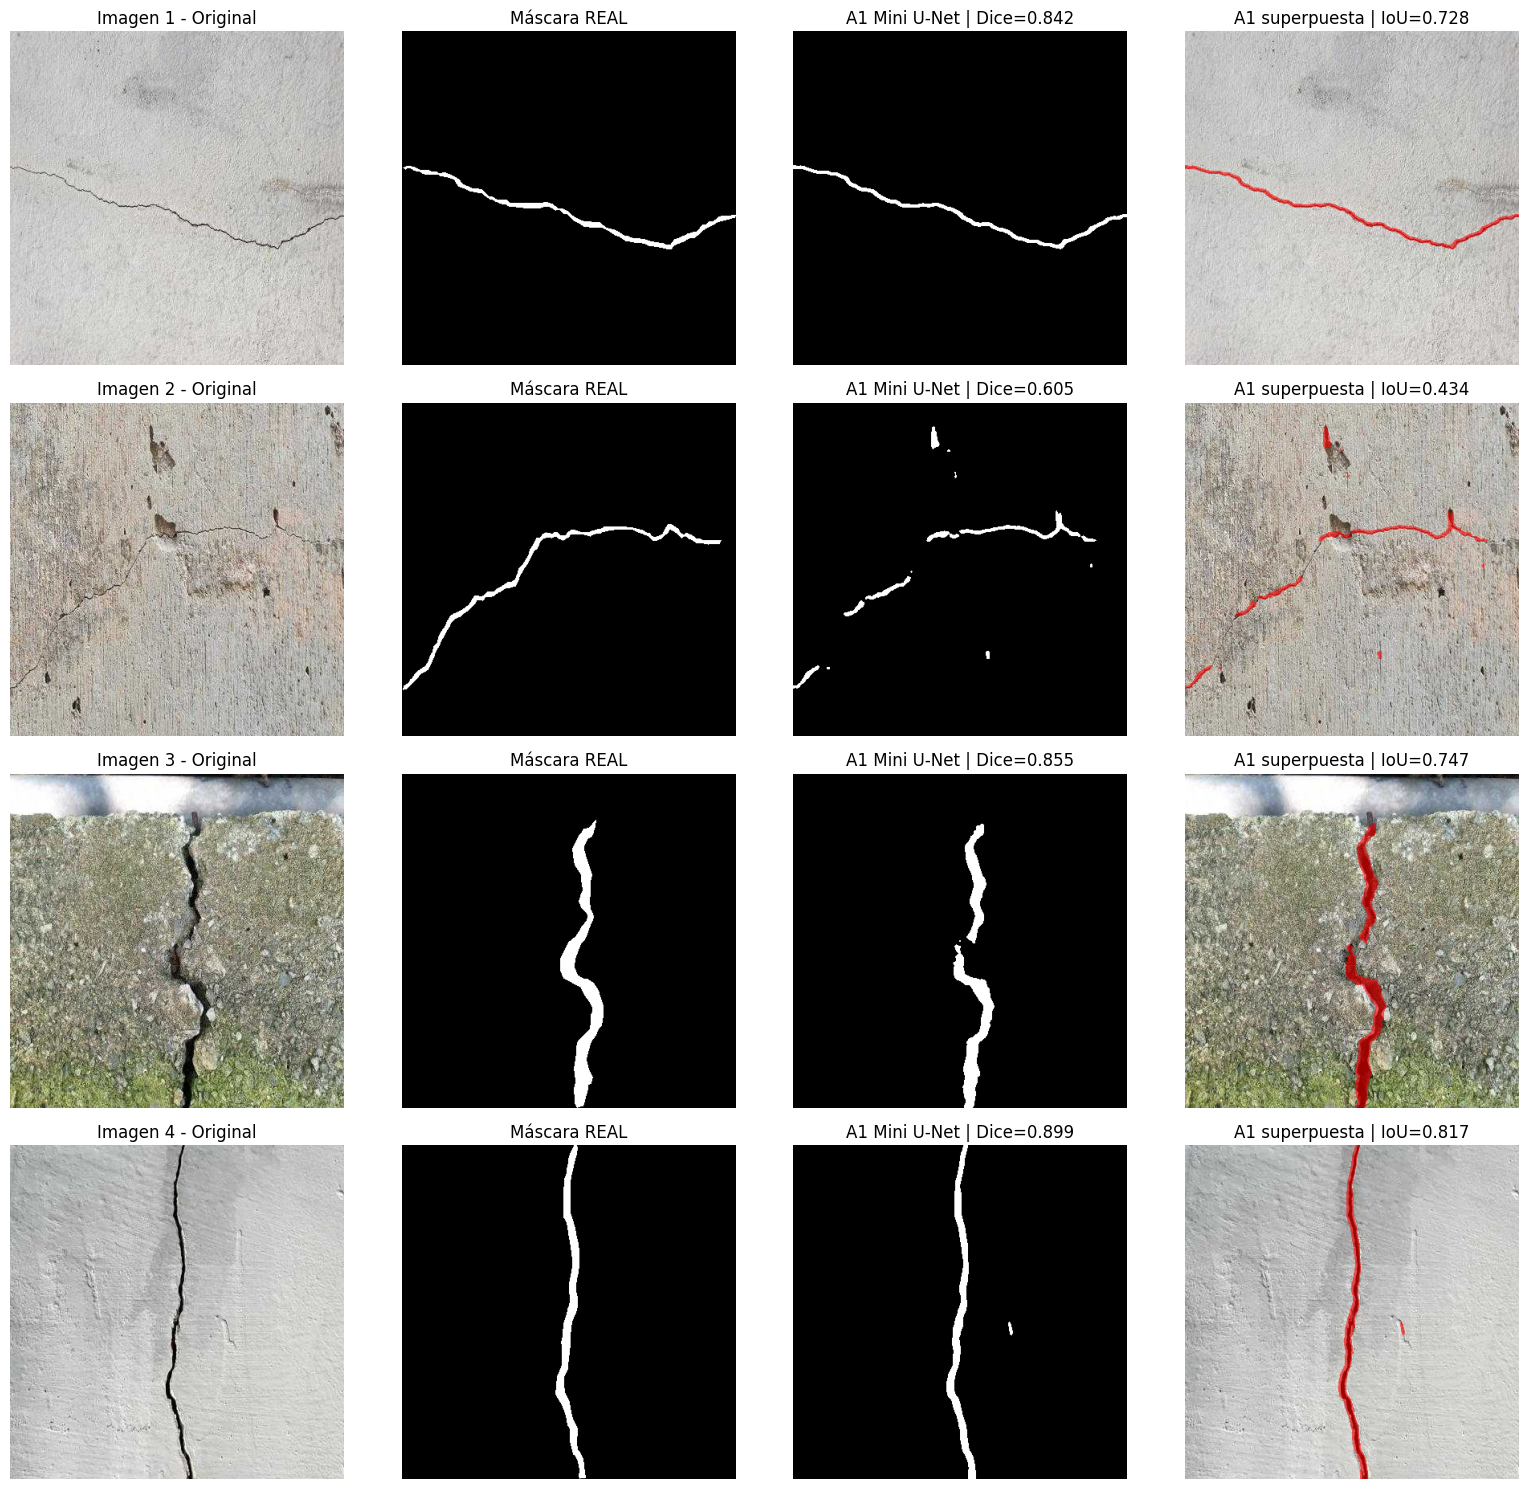

Dice e IoU por imagen (VALIDACIÓN):



,Imagen,ID,Dice_A1,IoU_A1
0,Imagen 1,1604.rf.7229a9adfa1c9ec285d55c965172ea32,0.842,0.728
1,Imagen 2,1605.rf.53a5ea427ceda0b3d6abbc79c64efc36,0.605,0.434
2,Imagen 3,1610.rf.3271e8c1058a3a701de2d96b621e9080,0.855,0.747
3,Imagen 4,1619.rf.5a42efe0c04aca69843e73fcc3a1a1bc,0.899,0.817


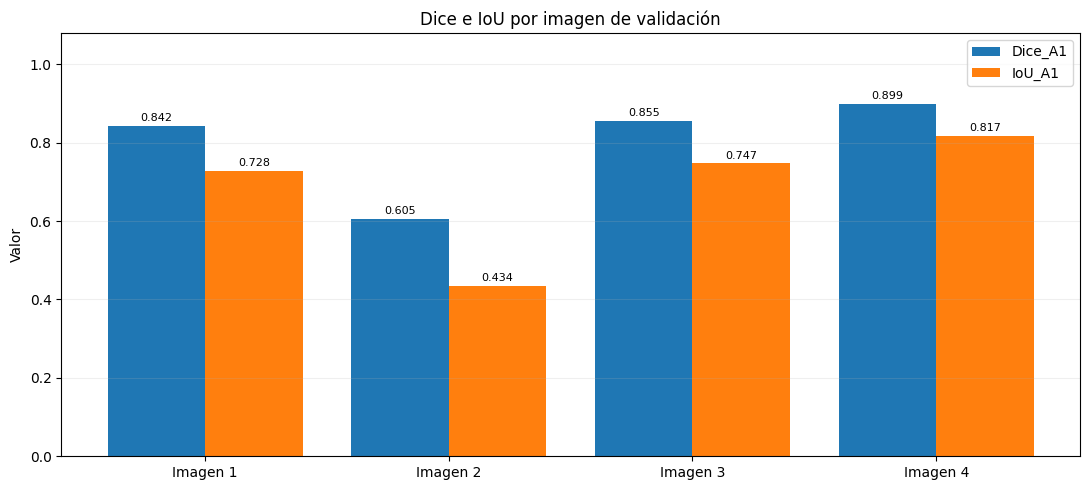

Estado: PASS - Predicciones y tabla generadas.


In [9]:
# ============================================================
# NB03 - CELDA 8: PREDICCIONES A0 vs A1 SOBRE LAS MISMAS IMÁGENES
#
# Objetivos:
#   1. Mostrar las 4 imágenes de VALIDACIÓN que usó NB02.
#   2. Si está disponible el checkpoint BEST de A0, comparar
#      su predicción con la de la Mini U-Net (A1).
#   3. Calcular Dice e IoU individuales y construir la tabla.
#
# IMPORTANTE:
#   - El checkpoint de A0 solo se LEE; no se modifica.
#   - NO utiliza imágenes de TEST.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def metricas_imagen(pred, real):
    tp = np.logical_and(pred == 1, real == 1).sum()
    fp = np.logical_and(pred == 1, real == 0).sum()
    fn = np.logical_and(pred == 0, real == 1).sum()
    dice = 2 * tp / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)
    return dice, iou


def superponer(imagen, pred):
    # Predicción en rojo sobre la fotografía.
    resultado = imagen.copy()
    zona = pred == 1
    resultado[zona] = 0.4 * resultado[zona] + 0.6 * np.array(
        [1.0, 0.0, 0.0]
    )
    return resultado


# ------------------------------------------------------------
# 1. PREDICCIÓN DE A0 (OPCIONAL)
# ------------------------------------------------------------

predicciones_a0_np = None

if CHECKPOINT_A0.is_file() and MODO_DATOS == "completo":

    estado_a0 = torch.load(
        CHECKPOINT_A0, map_location=device, weights_only=False
    )
    modelo_a0 = EncoderDecoder().to(device)
    modelo_a0.load_state_dict(
        estado_a0["model_state_dict"], strict=True
    )
    modelo_a0.eval()

    with torch.inference_mode():
        predicciones_a0_np = (
            torch.sigmoid(modelo_a0(imagenes_val)) >= UMBRAL
        ).float().cpu().numpy()

    print("A0 cargado: epoch BEST", estado_a0["epoch"])
else:
    print("Checkpoint A0 no disponible: se muestra solo A1.")

# ------------------------------------------------------------
# 2. FIGURA
# ------------------------------------------------------------

imagenes_np = imagenes_val.detach().cpu().numpy()
mascaras_np = mascaras_val.detach().cpu().numpy()
predicciones_np = predicciones_val.detach().cpu().numpy()

columnas = 5 if predicciones_a0_np is not None else 4
fig_pred, axes = plt.subplots(4, columnas, figsize=(4 * columnas, 15))

filas = []

for i in range(4):

    imagen = np.transpose(imagenes_np[i], (1, 2, 0))
    real = mascaras_np[i, 0]
    pred = predicciones_np[i, 0]

    dice, iou = metricas_imagen(pred, real)
    fila = {"Imagen": f"Imagen {i+1}", "ID": ids_val[i],
            "Dice_A1": round(dice, 3), "IoU_A1": round(iou, 3)}

    paneles = [
        (imagen, None, f"Imagen {i+1} - Original"),
        (real, "gray", "Máscara REAL"),
    ]

    if predicciones_a0_np is not None:
        pred_a0 = predicciones_a0_np[i, 0]
        dice_a0, iou_a0 = metricas_imagen(pred_a0, real)
        fila["Dice_A0"] = round(dice_a0, 3)
        fila["IoU_A0"] = round(iou_a0, 3)
        paneles.append((pred_a0, "gray",
                        f"A0 sin skip | Dice={dice_a0:.3f}"))

    paneles.append((pred, "gray", f"A1 Mini U-Net | Dice={dice:.3f}"))
    paneles.append((superponer(imagen, pred), None,
                    f"A1 superpuesta | IoU={iou:.3f}"))

    for j, (dato, cmap, titulo) in enumerate(paneles):
        if cmap:
            axes[i, j].imshow(dato, cmap=cmap, vmin=0, vmax=1)
        else:
            axes[i, j].imshow(dato)
        axes[i, j].set_title(titulo)
        axes[i, j].axis("off")

    filas.append(fila)

fig_pred.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. TABLA Y GRÁFICO DE BARRAS
# ------------------------------------------------------------

df_metricas = pd.DataFrame(filas)
print("Dice e IoU por imagen (VALIDACIÓN):\n")
display(df_metricas)

series = [c for c in ["Dice_A0", "Dice_A1", "IoU_A0", "IoU_A1"]
          if c in df_metricas.columns]

x = np.arange(len(df_metricas))
ancho = 0.8 / len(series)

fig_barras, ax = plt.subplots(figsize=(11, 5))

for k, serie in enumerate(series):
    barras = ax.bar(x - 0.4 + ancho * (k + 0.5),
                    df_metricas[serie], width=ancho, label=serie)
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(df_metricas["Imagen"])
ax.set_ylim(0, 1.08)
ax.set_ylabel("Valor")
ax.set_title("Dice e IoU por imagen de validación")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig_barras.tight_layout()
plt.show()

print("Estado: PASS - Predicciones y tabla generadas.")

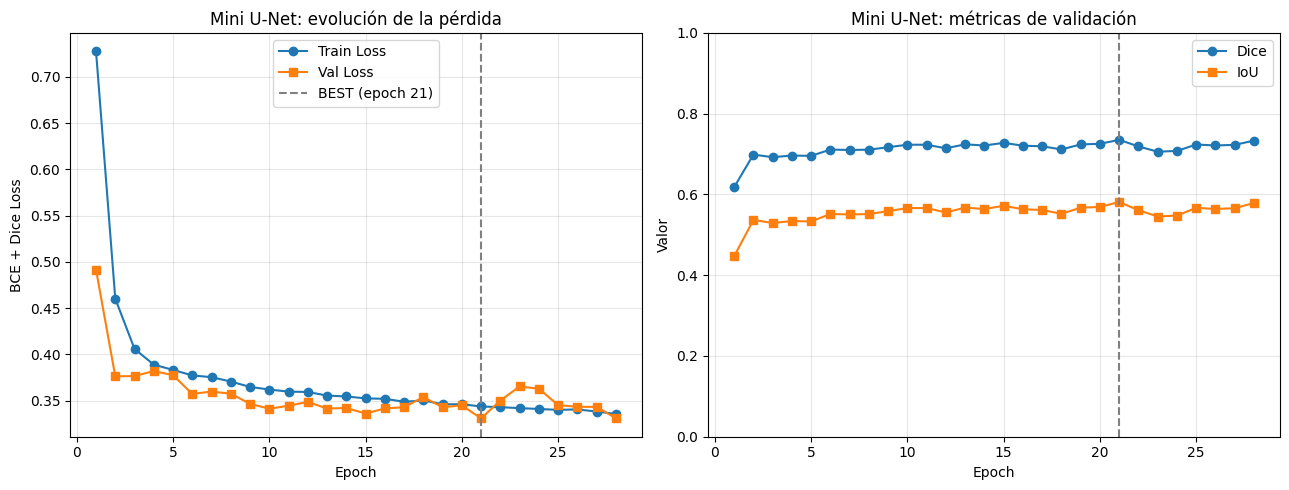

Comparación A0 vs A1 (VALIDACIÓN, no TEST):



,A0 Encoder-Decoder (sin skip),A1 Mini U-Net (con skip),Diferencia (A1 - A0)
Parámetros,106753.0000,118273.0000,11520.0000
Epochs ejecutadas,20.0000,28.0000,8.0000
Epoch BEST,13.0000,21.0000,8.0000
Val Loss BEST,0.3382,0.3309,-0.0074
Val Dice BEST,0.7290,0.7351,0.0061
Val IoU BEST,0.5736,0.5811,0.0075
Tiempo total (min),52.2175,27.7555,-24.4620
Tiempo medio por epoch (s),156.6524,59.4761,-97.1763



RESPALDO DE RESULTADOS NB03
OK | NB03_Historial_Entrenamiento.csv | 5.4 KB
OK | NB03_Metricas_4_Imagenes.csv | 0.3 KB
OK | NB03_Curvas_Entrenamiento.png | 110.5 KB
OK | NB03_Barras_4_Imagenes.png | 46.8 KB
OK | NB03_Predicciones_4_Imagenes.png | 2650.4 KB
OK | NB03_Resumen_Resultados.json | 1.8 KB
OK | checkpoint_best.pt | 1431.8 KB
OK | checkpoint_last.pt | 1432.9 KB
OK | NB03_Comparacion_A0_A1_VAL.csv | 0.5 KB

Estado: PASS - Resultados respaldados en /content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras/resultados/NB03_MiniUNet


In [10]:
# ============================================================
# NB03 - CELDA 9: EXPORTACIÓN DE RESULTADOS Y COMPARACIÓN A0/A1
#
# Objetivos:
#   1. Guardar historial, métricas y figuras de la Mini U-Net.
#   2. Crear un resumen JSON con configuración, resultados y
#      consumo de recursos (para el Integrante 4).
#   3. Construir la tabla comparativa A0 vs A1 en VALIDACIÓN.
#
# IMPORTANTE:
#   - NO entrena ni modifica el modelo.
#   - NO sobrescribe checkpoints (de A1 ni de A0).
#   - Las métricas son de VALIDACIÓN, no de TEST.
# ============================================================

import json
import platform
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Releer el historial desde el checkpoint LAST: así la celda
# funciona aunque la sesión de entrenamiento se haya reiniciado.
estado_last = torch.load(
    CHECKPOINT_LAST, map_location="cpu", weights_only=False
)
historial = estado_last["historial"]
tiempo_acumulado = estado_last["tiempo_acumulado_seg"]
df_historial = pd.DataFrame(historial)

# ------------------------------------------------------------
# 1. HISTORIAL Y MÉTRICAS POR IMAGEN
# ------------------------------------------------------------

ruta_historial = CARPETA_RESULTADOS / "NB03_Historial_Entrenamiento.csv"
ruta_metricas = CARPETA_RESULTADOS / "NB03_Metricas_4_Imagenes.csv"

df_historial.to_csv(ruta_historial, index=False, encoding="utf-8-sig")
df_metricas.to_csv(ruta_metricas, index=False, encoding="utf-8-sig")

# ------------------------------------------------------------
# 2. CURVAS DE ENTRENAMIENTO
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(df_historial["epoch"], df_historial["train_loss"],
             marker="o", label="Train Loss")
axes[0].plot(df_historial["epoch"], df_historial["val_loss"],
             marker="s", label="Val Loss")
axes[0].axvline(epoch_best, color="gray", linestyle="--",
                label=f"BEST (epoch {epoch_best})")
axes[0].set_title("Mini U-Net: evolución de la pérdida")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE + Dice Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_historial["epoch"], df_historial["val_dice"],
             marker="o", label="Dice")
axes[1].plot(df_historial["epoch"], df_historial["val_iou"],
             marker="s", label="IoU")
axes[1].axvline(epoch_best, color="gray", linestyle="--")
axes[1].set_title("Mini U-Net: métricas de validación")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Valor")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.tight_layout()

ruta_curvas = CARPETA_RESULTADOS / "NB03_Curvas_Entrenamiento.png"
fig.savefig(ruta_curvas, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# Figuras de la Celda 8.
ruta_predicciones = CARPETA_RESULTADOS / "NB03_Predicciones_4_Imagenes.png"
ruta_barras = CARPETA_RESULTADOS / "NB03_Barras_4_Imagenes.png"
fig_pred.savefig(ruta_predicciones, dpi=180, bbox_inches="tight")
fig_barras.savefig(ruta_barras, dpi=180, bbox_inches="tight")

# ------------------------------------------------------------
# 3. RESUMEN JSON (configuración + resultados + recursos)
# ------------------------------------------------------------

registro_minimo = min(historial, key=lambda r: r["val_loss"])

resumen = {
    "fecha_exportacion": datetime.now().isoformat(),
    "notebook": "NB03_MiniUNet",
    "arquitectura": "MiniUNet_con_skip",
    "skip_connections": [
        "encoder1 (16 canales, 416x416) -> concat antes de decoder2",
        "encoder2 (32 canales, 208x208) -> concat antes de decoder1"
    ],
    "parametros_entrenables": PARAMETROS_A1,
    "parametros_A0_referencia": PARAMETROS_A0,
    "diferencia_parametros_vs_A0": PARAMETROS_A1 - PARAMETROS_A0,
    "dataset": NOMBRE_DATASET,
    "imagenes_train": NUM_TRAIN,
    "imagenes_val": NUM_VAL,
    "resolucion": [IMAGE_SIZE, IMAGE_SIZE],
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "loss": "BCE + Dice",
    "optimizer": "Adam",
    "seed": SEED,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "umbral": UMBRAL,
    "epochs_ejecutadas": len(historial),
    "epoch_checkpoint_best": epoch_best,
    "checkpoint_best": {
        "train_loss": registro_best["train_loss"],
        "val_loss": registro_best["val_loss"],
        "val_dice": registro_best["val_dice"],
        "val_iou": registro_best["val_iou"],
        "val_precision": evaluacion_val["precision_global"],
        "val_recall": evaluacion_val["recall_global"],
        "val_dice_medio_por_imagen":
            evaluacion_val["dice_medio_por_imagen"]
    },
    "epoch_minima_val_loss_observada": registro_minimo["epoch"],
    "recursos": {
        "plataforma": "Google Colab" if EN_COLAB else "Local",
        "gpu": estado_last.get("gpu"),
        "pytorch": torch.__version__,
        "python": platform.python_version(),
        "tiempo_total_epochs_seg": tiempo_acumulado,
        "horas_gpu": tiempo_acumulado / 3600,
        "tiempo_medio_epoch_seg":
            float(df_historial["tiempo_epoch_seg"].mean()),
        "memoria_gpu_pico_entrenamiento_mb":
            float(df_historial["memoria_gpu_pico_mb"].max()),
        "inferencia_ms_por_imagen":
            evaluacion_val["inferencia_ms_por_imagen"],
        "tamano_checkpoint_best_mb":
            CHECKPOINT_BEST.stat().st_size / 1024**2
    },
    "metricas": "Validación; no son resultados de TEST",
    "checkpoints": ["checkpoint_best.pt", "checkpoint_last.pt"]
}

ruta_resumen = CARPETA_RESULTADOS / "NB03_Resumen_Resultados.json"

with open(ruta_resumen, "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=4, ensure_ascii=False)

# ------------------------------------------------------------
# 4. TABLA COMPARATIVA A0 vs A1 (VALIDACIÓN)
# ------------------------------------------------------------

# Valores de A0 tomados de NB02_Resumen_Resultados.json
# (Etapa 2, 26-oct-2026, misma GPU T4 y mismo protocolo).
A0 = {
    "Parámetros": 106753,
    "Epochs ejecutadas": 20,
    "Epoch BEST": 13,
    "Val Loss BEST": 0.338247,
    "Val Dice BEST": 0.729015,
    "Val IoU BEST": 0.573582,
    "Tiempo total (min)": 3133.048 / 60,
    "Tiempo medio por epoch (s)": 3133.048 / 20,
}

A1 = {
    "Parámetros": PARAMETROS_A1,
    "Epochs ejecutadas": len(historial),
    "Epoch BEST": epoch_best,
    "Val Loss BEST": registro_best["val_loss"],
    "Val Dice BEST": registro_best["val_dice"],
    "Val IoU BEST": registro_best["val_iou"],
    "Tiempo total (min)": tiempo_acumulado / 60,
    "Tiempo medio por epoch (s)":
        float(df_historial["tiempo_epoch_seg"].mean()),
}

df_comparacion = pd.DataFrame({
    "A0 Encoder-Decoder (sin skip)": A0,
    "A1 Mini U-Net (con skip)": A1,
})
df_comparacion["Diferencia (A1 - A0)"] = (
    df_comparacion.iloc[:, 1] - df_comparacion.iloc[:, 0]
)

if MODO_DATOS == "completo":
    print("Comparación A0 vs A1 (VALIDACIÓN, no TEST):\n")
    display(df_comparacion.round(4))
    ruta_comparacion = CARPETA_RESULTADOS / "NB03_Comparacion_A0_A1_VAL.csv"
    df_comparacion.to_csv(ruta_comparacion, encoding="utf-8-sig")
else:
    print("Modo piloto: no se compara con A0 (datos distintos).")
    ruta_comparacion = None

# ------------------------------------------------------------
# 5. VERIFICAR ARCHIVOS GENERADOS
# ------------------------------------------------------------

archivos_generados = [
    ruta_historial, ruta_metricas, ruta_curvas, ruta_barras,
    ruta_predicciones, ruta_resumen, CHECKPOINT_BEST, CHECKPOINT_LAST
]
if ruta_comparacion is not None:
    archivos_generados.append(ruta_comparacion)

print("\n" + "=" * 65)
print("RESPALDO DE RESULTADOS NB03")
print("=" * 65)

for archivo in archivos_generados:
    assert archivo.is_file() and archivo.stat().st_size > 0
    print(f"OK | {archivo.name} | {archivo.stat().st_size / 1024:.1f} KB")

print("\nEstado: PASS - Resultados respaldados en", CARPETA_RESULTADOS)